# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

---

### Group Information

Fill this in before you submit.

**Group number:**

| Full Name | UNI |
|-----------|-----|
|Anzhi Chen |ac5921|
|Yimeng Lei |yl6042|

**Public GitHub repository URL:https://github.com/anzhichen1999/Fall2026_QMSS5074GR_Project_1.git**

## How to Complete and Submit This Project

**Due: Monday, October 19, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_1.ipynb`.

### 1. Get started

Everything you need comes in the project folder. No separate downloads are needed:

```
Fall2026_QMSS5074GR_Project_1/
├── Project_1.ipynb
└── data/
    ├── WHR_2023.csv
    └── newcountryvars.csv
```

1. Unzip the folder and open `Project_1.ipynb`.
2. Keep the `data` folder next to the notebook and don't rename any files. The code reads the data from `data/WHR_2023.csv` and `data/newcountryvars.csv`.
3. Run the first code cell in Section 0 to install the required packages.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible.
- Fill in the **Group Information** cell at the top, including your GitHub link.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 1 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_1` folder, with the `data` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_1/
    ├── Project_1.ipynb
    └── data/
        ├── WHR_2023.csv
        └── newcountryvars.csv
```

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart & Run All finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` and the `data` folder are in `Project_1/` in your public group repository

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [1]:
# Install the packages used in this project (quick if they are already installed)
%pip install -q pandas numpy scikit-learn matplotlib tensorflow shap

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# If you store the project on google drive,
# comment out Option A above and uncomment the line below:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/Fall2026_QMSS5074GR_Project_1/data/WHR_2023.csv'

# If you store the project locally, comment out Option A above and uncomment the line below:
# DATA_PATH = 'data/WHR_2023.csv'

# Load the dataset
whr_df = pd.read_csv(DATA_PATH)

# Inspect the first few rows to understand the structure
whr_df.head()


Mounted at /content/drive


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
0,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535
1,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525
2,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187
3,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158
4,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394


In [3]:
# Convert the regression target ('happiness_score') into classification labels
# We'll use quintiles to create 5 happiness categories: Very Low, Low, Average, High, Very High

# Define quintiles
whr_df['happiness_category'] = pd.qcut(whr_df['happiness_score'],
                                       q=5, labels=['Very Low', 'Low','Average', 'High', 'Very High'])

# Select features and target
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Convert y_train and y_test to numerical labels
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes

### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

*Replace this section with your response.*

**Q1:**
The code assigns the 5 categories from "very low" to "very high" to 5 numbers ranging from "0" to "1" with "very low" being "0" and "very high" being "1"

**Q2:**
y_train_label is essentially the number listed in Q1 and y_train is a panda series that holds those names for each category.


### Add New Data

In [4]:
# Country development indicators to merge

#Google Colab ---
from google.colab import drive
drive.mount('/content/drive')  # safe to rerun; skips if already mounted

COUNTRY_PATH = '/content/drive/MyDrive/Fall2026_QMSS5074GR_Project_1/data/newcountryvars.csv'

# If you store the project locally, comment out Option A above and uncomment the line below:
# COUNTRY_PATH = 'data/newcountryvars.csv'

countrydata = pd.read_csv(COUNTRY_PATH)

countrydata.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


In [5]:
matched = whr_df['country'].isin(countrydata['country_name'])
matched.sum(), whr_df.loc[~matched, 'country'].tolist()

(np.int64(128),
 ['Czechia',
  'Taiwan Province of China',
  'Vietnam',
  'Hong Kong S.A.R. of China',
  'Congo (Brazzaville)',
  'North Macedonia',
  'State of Palestine',
  'Turkiye',
  'Congo (Kinshasa)'])

In [6]:
unmatched_other = countrydata.loc[~countrydata['country_name'].isin(whr_df['country']), 'country_name']
sorted(unmatched_other)

['Angola',
 'Azerbaijan',
 'Belarus',
 'Belize',
 'Bhutan',
 'Brunei',
 'Burundi',
 'Central African Republic',
 'Congo',
 'Cuba',
 'Czech Republic',
 'Democratic Republic of the Congo',
 'Djibouti',
 'Equatorial Guinea',
 'Eritrea',
 'Fiji',
 'Guinea-Bissau',
 'Guyana',
 'Haiti',
 'Hong Kong',
 'Kuwait',
 'Lesotho',
 'Libya',
 'Macedonia',
 'Maldives',
 'North Korea',
 'Oman',
 'Palestine',
 'Papua New Guinea',
 'Puerto Rico',
 'Qatar',
 'Rwanda',
 'Samoa',
 'Solomon Islands',
 'Somalia',
 'South Sudan',
 'Sudan',
 'Suriname',
 'Swaziland',
 'Syria',
 'Timor-Leste',
 'Trinidad and Tobago',
 'Turkey',
 'Turkmenistan',
 'VietNam',
 'Yemen']

In [7]:
#manully craft a dictionary for mapping.
name_map = {
    'Congo': 'Congo (Brazzaville)',
    'Democratic Republic of the Congo': 'Congo (Kinshasa)',
    'Czech Republic': 'Czechia',
    'Hong Kong': 'Hong Kong S.A.R. of China',
    'Macedonia': 'North Macedonia',
    'Palestine': 'State of Palestine',
    'Turkey': 'Turkiye',
    'VietNam': 'Vietnam',
}
countrydata['country_name'] = countrydata['country_name'].replace(name_map)

We therefore chose the left merge becuase it will just append the variables to countries we need. A right merge may leave counties with no happiness score here which is not usable for our analysis. Essentially join is just left merge.

In [8]:
# Merge in new data to X_train and X_test by taking "country" from first table and "country_name" from 2nd table.
# Also check which countries are common in both the datasets, and which type of merge will you perform for the best results.
# Hint: Look at the 'how' parameter of the pandas merge function.
# Note: Your merge must keep every row of X_train and X_test so they stay aligned with y_train and y_test.
# Some country names differ between the two files; you may optionally harmonize them before merging.

cd = countrydata.set_index('country_name')

X_train = X_train.join(cd, on='country')
X_test = X_test.join(cd, on='country')


In [9]:
X_train.head(1)

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
126,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397


---

## 1. Exploratory Data Analysis and Visualization (EDAV)

In [10]:
print(X_train.dtypes)

country                           object
region                            object
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

*Replace this section with your response.*

**countries and regions are object while the rest and floating numbers. I assume this is what the question is asking? if not you can use the following cell for more info**

In [11]:
print(X_train.shape, X_test.shape)

(95, 15) (42, 15)


### Missing Values Analysis

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [12]:
# Your code here:
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
pd.DataFrame({'number of missing': X_train.isna().sum(),
              'percentage of missing missing': (X_train.isna().mean() * 100).round(1)}).sort_values('number of missing', ascending=False)

,number of missing,percentage of missing missing
population_below_poverty_line,11,11.6
mean_years_of_schooling,2,2.1
expected_years_of_schooling,2,2.1
life_expectancy,2,2.1
gni,2,2.1
population,1,1.1
hdi,1,1.1
generosity,0,0.0
freedom_to_make_life_choices,0,0.0
healthy_life_expectancy,0,0.0


In [14]:
pd.DataFrame({'number of missing': X_test.isna().sum(),
              'percentage of missing': (X_test.isna().mean() * 100).round(1)}).sort_values('number of missing', ascending=False)

,number of missing,percentage of missing
healthy_life_expectancy,1,2.4
mean_years_of_schooling,1,2.4
gni,1,2.4
life_expectancy,1,2.4
expected_years_of_schooling,1,2.4
population_below_poverty_line,1,2.4
region,0,0.0
generosity,0,0.0
freedom_to_make_life_choices,0,0.0
social_support,0,0.0


In [15]:
X_train[X_train.isna().any(axis=1)]

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
6,Norway,Western Europe,1.994,1.521,0.544,0.752,0.212,0.463,5305383.0,NaN,0.949423,81.711,17.67187,12.746420,67614.35348
45,Cyprus,Western Europe,1.824,1.224,0.580,0.455,0.104,0.050,1179551.0,NaN,0.855646,80.332,14.25613,11.695230,29458.52269
33,Kosovo,Central and Eastern Europe,1.374,1.269,0.372,0.639,0.275,0.045,1895250.0,30.0,0.786000,NaN,NaN,NaN,NaN
0,Finland,Western Europe,1.888,1.585,0.535,0.772,0.126,0.535,5523231.0,NaN,0.894517,81.006,17.04792,11.194000,38868.13552
9,New Zealand,North America and ANZ,1.842,1.544,0.513,0.672,0.230,0.471,4705818.0,NaN,0.914900,82.026,19.22820,12.503000,32870.07836
24,Singapore,Southeast Asia,2.168,1.354,0.607,0.660,0.170,0.561,5708844.0,NaN,0.924866,83.209,15.40000,11.572410,78162.32387
26,Taiwan Province of China,East Asia,1.890,1.372,0.492,0.562,0.067,0.178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,Australia,North America and ANZ,1.899,1.497,0.532,0.677,0.242,0.310,24450561.0,NaN,0.938680,82.537,20.43272,13.175100,42822.19627
8,Luxembourg,Western Europe,2.200,1.357,0.549,0.710,0.149,0.418,583455.0,NaN,0.898465,81.881,13.86373,11.950833,62470.59129
29,Saudi Arabia,Middle East and North Africa,1.861,1.370,0.351,0.682,0.093,0.170,32938213.0,NaN,0.846602,74.444,16.11227,9.627520,51320.11323


However, I notice that the qeustion is essentially asking for "a table" where "a" can be one and one only. So:

In [16]:
pd.concat({'train': pd.DataFrame({'number of missing': X_train.isna().sum(), 'percentage of missing': (X_train.isna().mean() * 100).round(1)}), 'test': pd.DataFrame({'number of missing': X_test.isna().sum(), 'percentage of missing': (X_test.isna().mean() * 100).round(1)}), 'countries': X_train.isna().apply(lambda col: ', '.join(X_train.loc[col, 'country'])).to_frame('missing in train')}, axis=1).sort_values(('train', 'number of missing'), ascending=False).loc[lambda d: d[('train', 'number of missing')] + d[('test', 'number of missing')] > 0]

train                        \
                              number of missing percentage of missing   
population_below_poverty_line                11                  11.6   
mean_years_of_schooling                       2                   2.1   
expected_years_of_schooling                   2                   2.1   
life_expectancy                               2                   2.1   
gni                                           2                   2.1   
population                                    1                   1.1   
hdi                                           1                   1.1   
healthy_life_expectancy                       0                   0.0   

                                           test                        \
                              number of missing percentage of missing   
population_below_poverty_line                 1                   2.4   
mean_years_of_schooling                       1                   2.4   
expected_years_of_schooling                   1                   2.4   
life_expectancy                               1                   2.4   
gni                                           1                   2.4   
population                                    0                   0.0   
hdi                                           0                   0.0   
healthy_life_expectancy                       1                   2.4   

                                                                       countries  
                                                                missing in train  
population_below_poverty_line  Norway, Cyprus, Finland, New Zealand, Singapor...  
mean_years_of_schooling                         Kosovo, Taiwan Province of China  
expected_years_of_schooling                     Kosovo, Taiwan Province of China  
life_expectancy                                 Kosovo, Taiwan Province of China  
gni                                             Kosovo, Taiwan Province of China  
population                                              Taiwan Province of China  
hdi                                                     Taiwan Province of China  
healthy_life_expectancy

In [17]:
X_train, y_train, y_train_labels = [d[X_train['country'] != 'Taiwan Province of China'] for d in (X_train, y_train, y_train_labels)]

### Distribution of Key Numerical Features

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

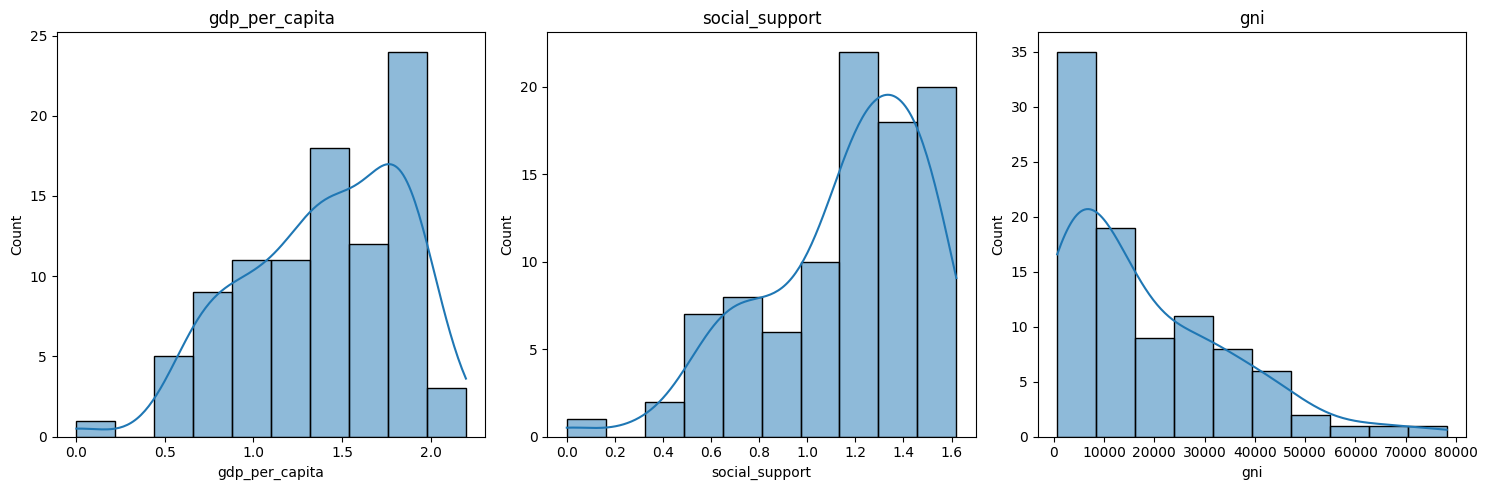

In [18]:
# Your plotting code here:

#we hereby want to select gdp, gini and social support.

features = ['gdp_per_capita', 'social_support', 'gni']

fig, axes = plt.subplots(1, len(features), figsize=(15, 5))
for axe, j in zip(axes, features):
    sns.histplot(X_train[j], bins=10, kde=True, ax=axe)
    axe.set_title(j)
plt.tight_layout()


For gdp_per_capita, like most countries are postioned from middle to high, and being very left-skewed

For social_support, most countries have high scores babove 1(1.1–1.6), so this one is also left-skewed. Like gdp it also has an outlier of 0 likely being Venezuela.

For gni it is very right scale. No apparent outliers here.

### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

As the questiuon explicitly ask for visualizations with "s" here. So i will use 2 strategies: one being count plots and second one being bar charts.

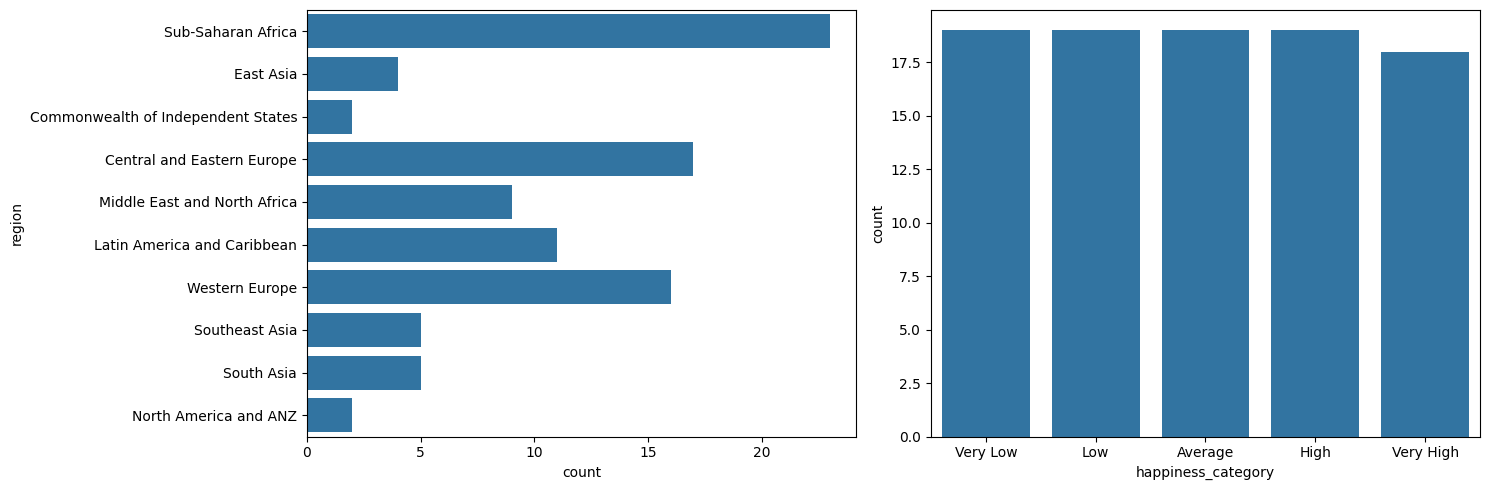

In [19]:
#
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(y=X_train['region'], ax=axes[0])
sns.countplot(x=y_train, ax=axes[1])
plt.tight_layout()

For 5 categories, the number for each is very similar and there's no outlier. For regions however, it is not evenlly distributed.  Sub-Saharan Africa has the most countries , then Central and Eastern Europe and Western Europe. North America and ANZ and the Commonwealth of Independent States have only 2 each (which is understandable)

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

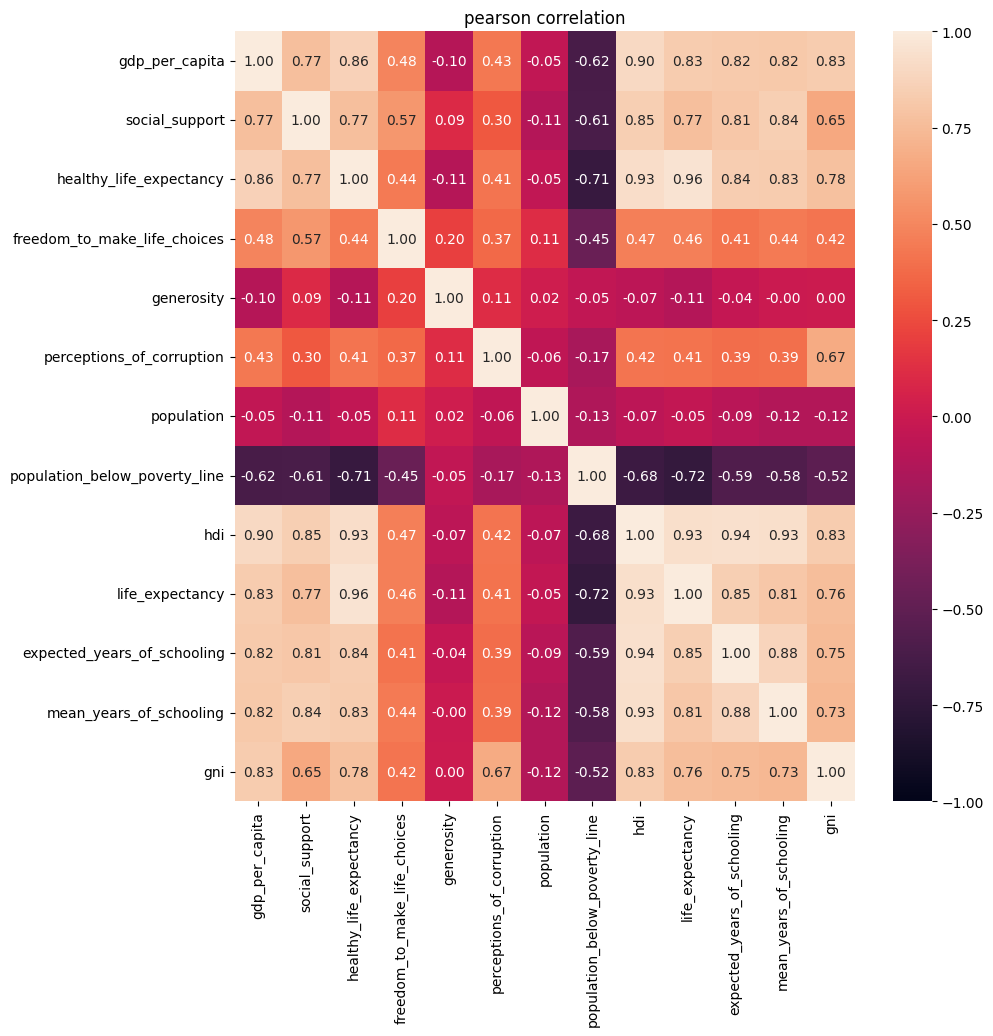

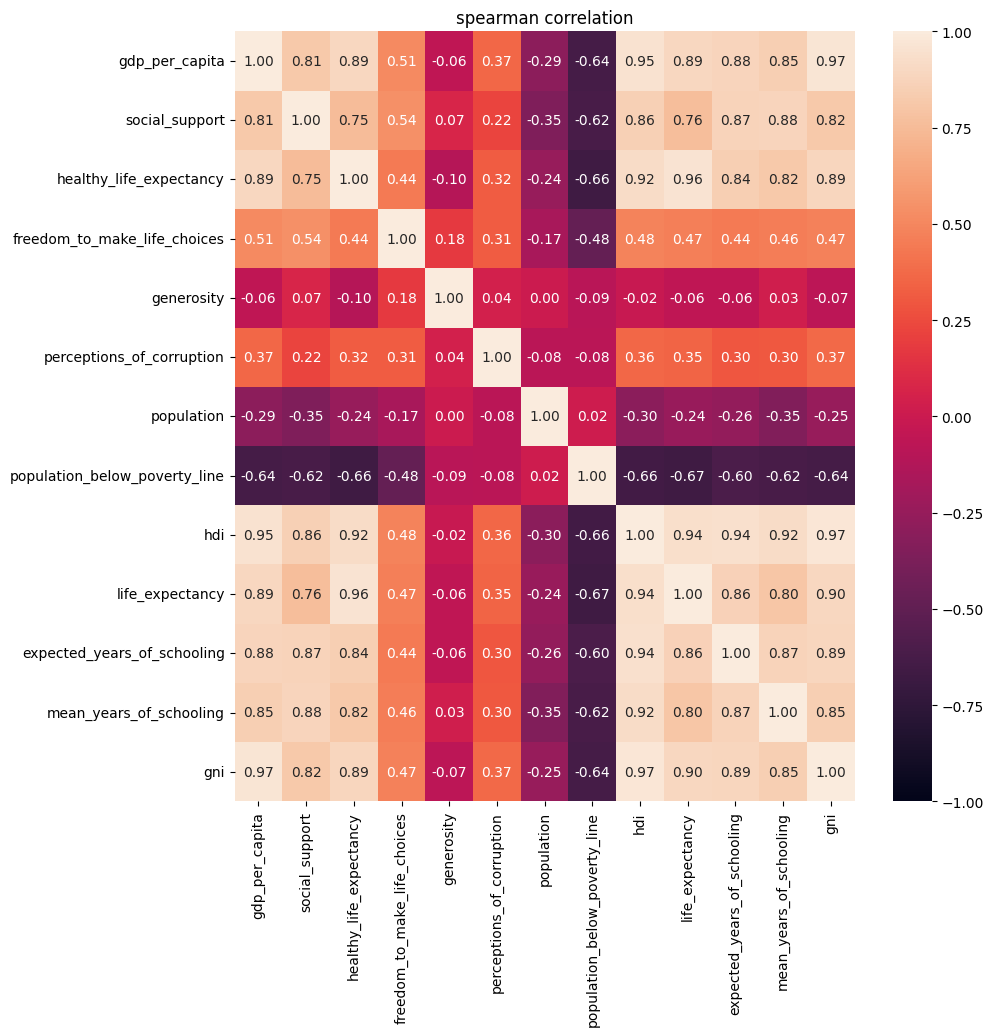

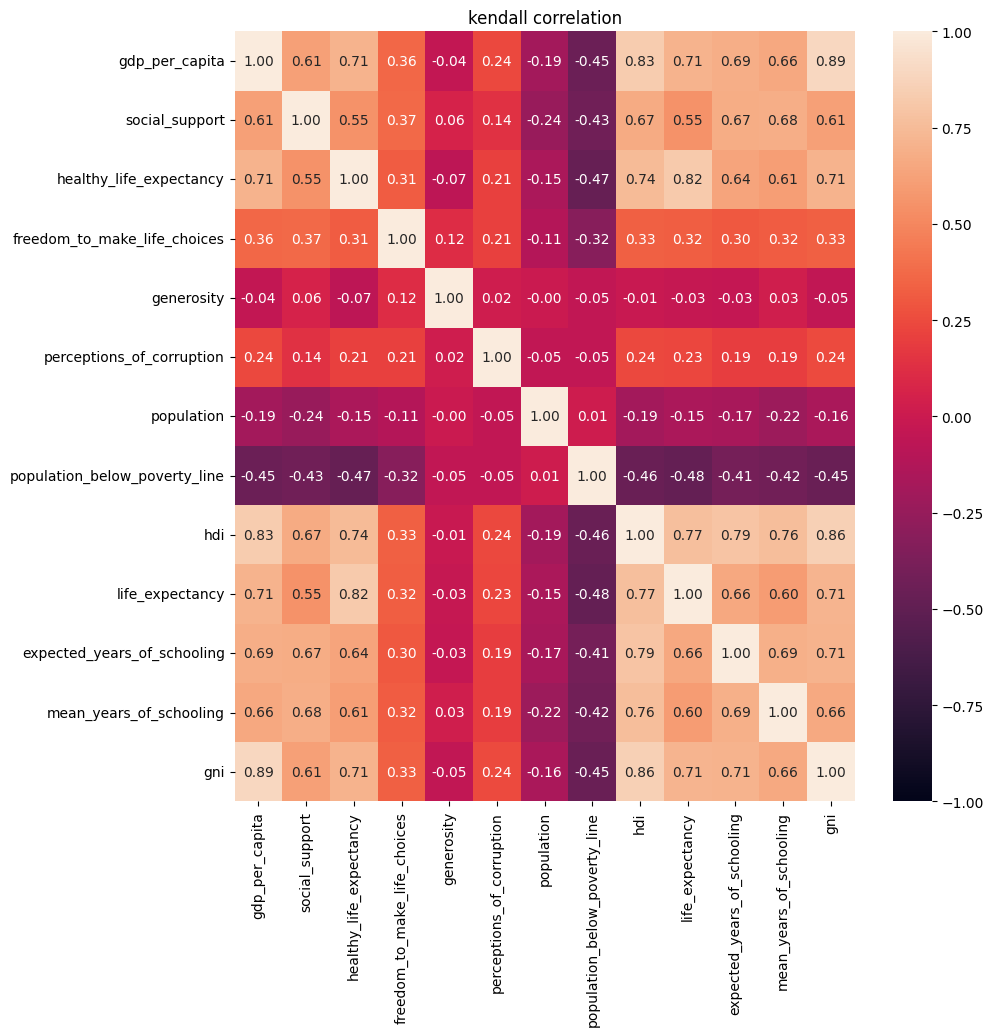

In [20]:
# Your code here:
num = X_train.select_dtypes(include='number')

for m in ['pearson', 'spearman', 'kendall']:
    plt.figure(figsize=(10, 10))
    sns.heatmap(num.corr(method=m), annot=True, fmt='.2f', vmin=-1, vmax=1)
    plt.title(f'{m} correlation')
    plt.show()

In [21]:
#Let us just filter the colinearity
import numpy as np
corr = num.corr(method='spearman')
corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().loc[lambda s: s.abs() >= 0.8].sort_values(ascending=False)

hdi                          gni                            0.970234
gdp_per_capita               gni                            0.968048
healthy_life_expectancy      life_expectancy                0.955135
gdp_per_capita               hdi                            0.950489
hdi                          expected_years_of_schooling    0.942138
                             life_expectancy                0.936204
healthy_life_expectancy      hdi                            0.920318
hdi                          mean_years_of_schooling        0.918355
life_expectancy              gni                            0.898253
gdp_per_capita               life_expectancy                0.894090
                             healthy_life_expectancy        0.893187
expected_years_of_schooling  gni                            0.890364
healthy_life_expectancy      gni                            0.887608
gdp_per_capita               expected_years_of_schooling    0.875689
social_support               mean_years_of_schooling        0.875447
                             expected_years_of_schooling    0.869896
expected_years_of_schooling  mean_years_of_schooling        0.869446
life_expectancy              expected_years_of_schooling    0.861235
social_support               hdi                            0.856993
mean_years_of_schooling      gni                            0.847349
gdp_per_capita               mean_years_of_schooling        0.845191
healthy_life_expectancy      expected_years_of_schooling    0.844299
                             mean_years_of_schooling        0.818999
social_support               gni                            0.816994
gdp_per_capita               social_support                 0.814748
life_expectancy              mean_years_of_schooling        0.804485
dtype: float64

Just going from top to bottom you can see every collinear relationship.

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

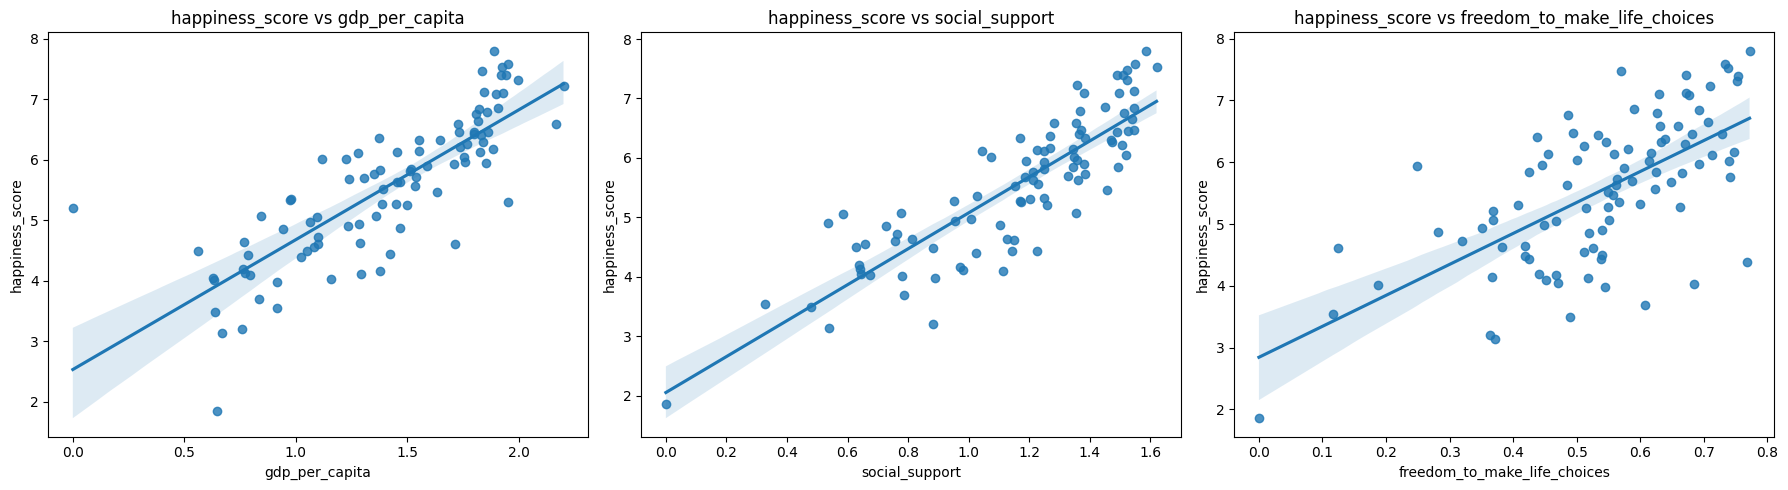

In [22]:
# Your plotting code(s) here:
score = whr_df.loc[X_train.index, 'happiness_score']
features_rq = ['gdp_per_capita', 'social_support', 'freedom_to_make_life_choices']

plt.figure(figsize=(18, 5))
for i, col in enumerate(features_rq):
    plt.subplot(1, 3, i+1)
    sns.regplot(x=X_train[col], y=score)
    plt.title(f'happiness_score vs {col}')
plt.tight_layout()
plt.show()

Apparently they all increase with happniess score.

In [23]:
cols = ['happiness', 'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'gni', 'hdi']
corr = X_train[features_rq].assign(happiness_score=score)[['happiness_score'] + features_rq].corr().round(4)
corr.where(np.tril(np.ones(corr.shape, dtype=bool))).fillna('')

,happiness_score,gdp_per_capita,social_support,freedom_to_make_life_choices
happiness_score,1.0000,,,
gdp_per_capita,0.8163,1.0,,
social_support,0.8583,0.7684,1.0,
freedom_to_make_life_choices,0.6506,0.4845,0.572,1.0


GDP and social support are correlated at 0.7684, so they carry similar info

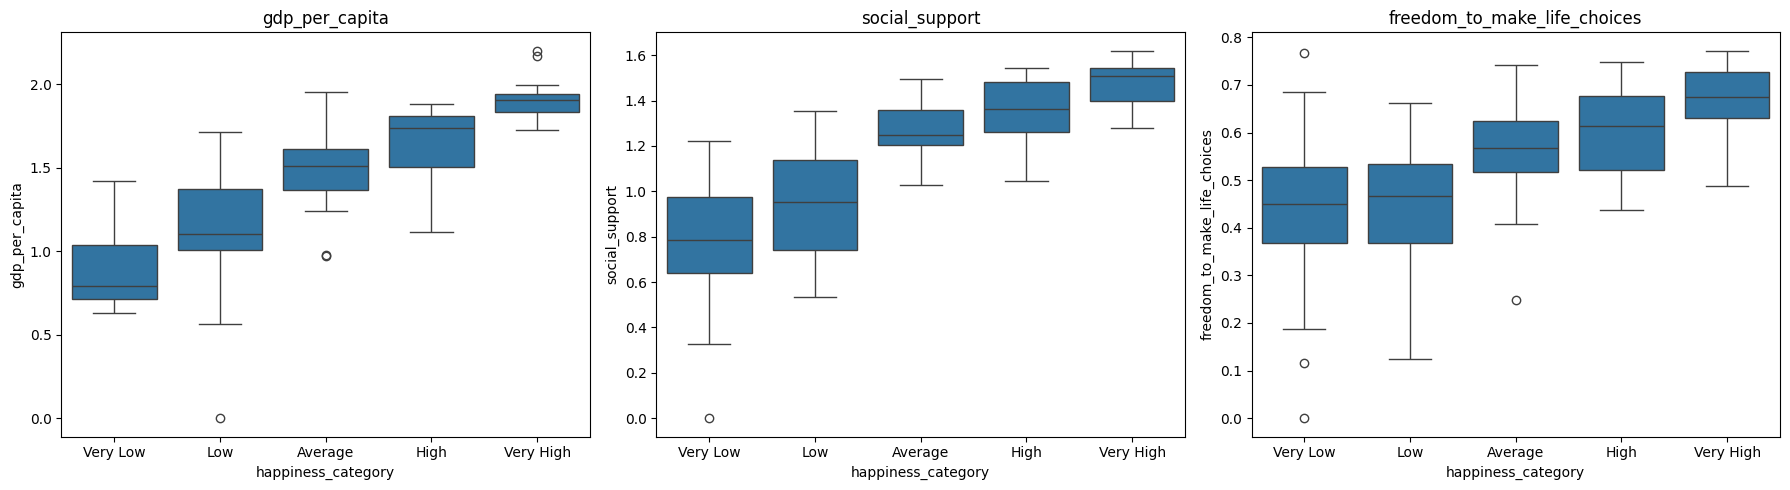

In [24]:
plt.figure(figsize=(18, 5))
for i, col in enumerate(features_rq):
    plt.subplot(1, 3, i+1)
    sns.boxplot(x=y_train, y=X_train[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

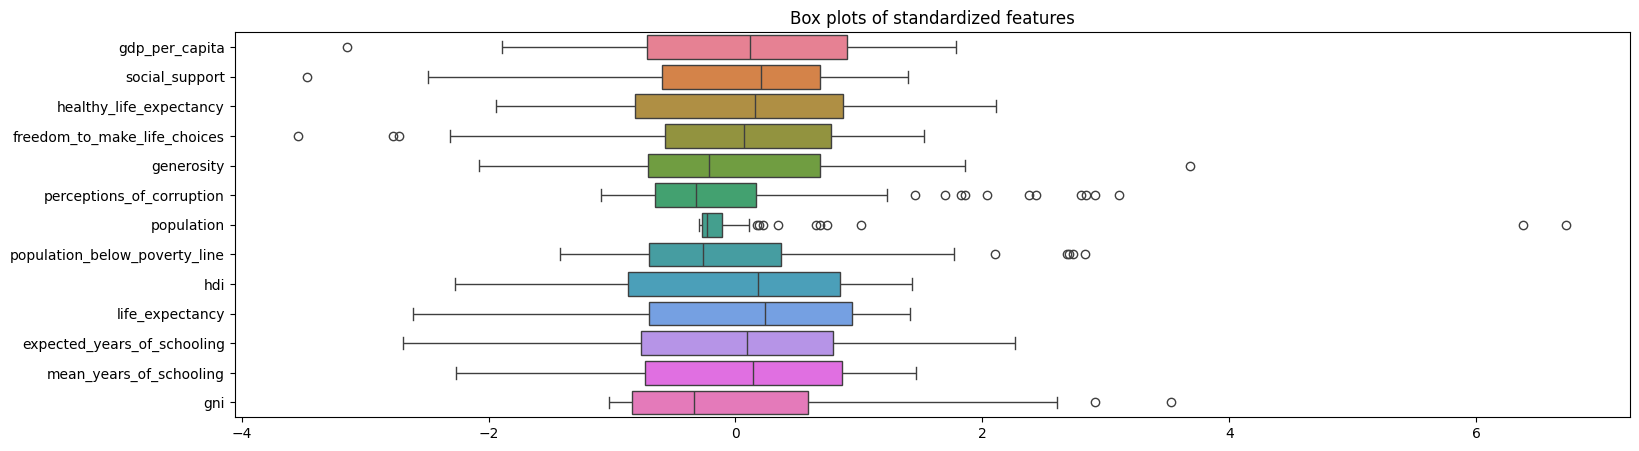

In [25]:
z = (num - num.mean()) / num.std()

plt.figure(figsize=(18, 5))
sns.boxplot(data=z, orient='h')
plt.title('Box plots of standardized features')
plt.show()

In [26]:
# Your code here:
pd.set_option('display.max_colwidth', None)

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
pd.DataFrame({'low outliers': (num < q1 - 1.5 * iqr).apply(lambda col: ', '.join(X_train.loc[col, 'country'])),
              'high outliers': (num > q3 + 1.5 * iqr).apply(lambda col: ', '.join(X_train.loc[col, 'country']))})

,low outliers,high outliers
gdp_per_capita,Venezuela,
social_support,Afghanistan,
healthy_life_expectancy,,
freedom_to_make_life_choices,"Comoros, Afghanistan, Turkiye",
generosity,,Indonesia
perceptions_of_corruption,,"Netherlands, Norway, Denmark, Finland, New Zealand, Estonia, Singapore, Luxembourg, Sweden, United Kingdom, Hong Kong S.A.R. of China"
population,,"India, Nigeria, Brazil, Indonesia, Egypt, Mexico, Vietnam, Pakistan, Ethiopia, China"
population_below_poverty_line,,"Madagascar, Nigeria, Sierra Leone, Zimbabwe, Zambia"
hdi,,
life_expectancy,,


Sifnifixant anomolies are highlighted in the table above. I think we can take log of gini especially with the box chart at the very neginning of this assignment. We can apply the same to other varibaoles like population as well.

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.

*Replace this section with your response.*

**Q1**Happiness goes up with social support, GDP with health, education, HDI and GNI.  Many features move together: for example, hdi and gni asthere are 26 pairs have r ≥ 0.8, so several features carry almost the same information. The 5 happiness classes are almost equal in size, so there is no class imbalance, but neighboring classes  overlap a lot.'

**Q2**
For outliers, you can reference the table above for more information and I will not copy and paste them here. I have delte Taiwan for it hasing all values missing

**Q3**
For feature engineering, we will log-transform population and gni because they are very right-skewed. We will do the same to other highly skewed terms

**Q4** Apparently we can fill missing numeric values with the median instead of 0, because 0 would wrongly say that rich countries have 0% poverty which is not true.

---

## 2. Feature Engineering

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [27]:
# Your code here: I use Claude to do this step as I do not recall how to determine which variable is
# more suitable for log transformation
skew = pd.DataFrame({'before': num.skew(), 'after_log': np.log1p(num).skew()}).round(2)
log_features = skew[(skew.before > 1) & (skew.after_log.abs() < skew.before.abs() / 2)].index.tolist()
skew, log_features

(                               before  after_log
 gdp_per_capita                  -0.53      -1.13
 social_support                  -0.94      -1.49
 healthy_life_expectancy         -0.35      -0.52
 freedom_to_make_life_choices    -0.96      -1.38
 generosity                       0.55       0.33
 perceptions_of_corruption        1.60       1.40
 population                       6.21       0.16
 population_below_poverty_line    1.15      -0.37
 hdi                             -0.50      -0.62
 life_expectancy                 -0.69      -0.91
 expected_years_of_schooling     -0.24      -0.81
 mean_years_of_schooling         -0.47      -1.20
 gni                              1.24      -0.45,
 ['population', 'population_below_poverty_line', 'gni'])

In [28]:
log_features = ['population', 'gni','population_below_poverty_line']

for col in log_features:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

X_train[log_features].skew()

,0
population,0.161853
gni,-0.446517
population_below_poverty_line,-0.371475


### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [29]:
# Your code here:
for X in (X_train, X_test):
    X['gdp_x_social_support'] = X['gdp_per_capita'] * X['social_support']
    X['gdp_x_freedom'] = X['gdp_per_capita'] * X['freedom_to_make_life_choices']

X_train[['gdp_x_social_support', 'gdp_x_freedom', 'gdp_per_capita', 'social_support', 'freedom_to_make_life_choices']].corrwith(y_train_labels, method='spearman')

,0
gdp_x_social_support,0.874269
gdp_x_freedom,0.851500
gdp_per_capita,0.837619
social_support,0.836636
freedom_to_make_life_choices,0.617383


---

## 3. Data Preprocessing

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [30]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the preprocessing pipelines for both numeric and categorical data.

numeric_features = X_train.select_dtypes(include='number')   # drops the non-numerical 'country' and 'region'
numeric_features=numeric_features.columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),   # changed from constant 0 (see explanation below)
    ('scaler', StandardScaler())])

categorical_features = ['region']

#Replacing missing values with Modal value and then one hot encoding.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

# final preprocessor object set up with ColumnTransformer
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

#Fit your preprocessor object
preprocess=preprocessor.fit(X_train)
print(f"{len(numeric_features)} numeric features:", numeric_features)

15 numeric features: ['gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'population', 'population_below_poverty_line', 'hdi', 'life_expectancy', 'expected_years_of_schooling', 'mean_years_of_schooling', 'gni', 'gdp_x_social_support', 'gdp_x_freedom']


### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

*Replace this section with your response.*

The preprocessor fills in missing values (median for numbers, most common region for region), puts all numeric features on the same scale with mean=0, sd=1, and turns region into one 0/1 column per region, ignoring any region it has never seen. It drops country because it is only a name, and it learns everything from the training set only, so no information get out from the test data.

We made two changes: (1) we fill missing numbers with the median instead of 0, because 0 is unrealistic for most features like 0 years of life expectancy, and we set sparse_output=False so the output is a normal table that Keras and SHAP can use. The median is a typical value that is not affected by outliers, and since only a few values are missing, it does not really changes the data

In [31]:
# function to transform data with preprocessor

def preprocessor(data):
    preprocessed_data=preprocess.transform(data)
    return preprocessed_data

### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

*Replace this section with your response.*

The preprocessor object does not really learn but does the preparation work fill including the one-hot encode region mentioned above.

The preprocess object learned the description of the training data including so it has learned the medians, means, sd.

The preprocessor function is essentially a function that preprocess data. I get confused by this one and consult claude: a normal Python function you wrote yourself. It works on data: it takes a table of countries and returns a cleaned table of numbers

The preprocessed_data is the result. It is the cleaned table of numbers the function returns.

In [32]:
# check shape of X data after preprocessing it using our new function
preprocessor(X_train).shape

(94, 25)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [33]:
from sklearn.ensemble import RandomForestClassifier
import joblib

model = RandomForestClassifier(random_state=42).fit(preprocessor(X_train), y_train)

joblib.dump(preprocess, 'preprocessor.joblib')
joblib.dump(model, 'random_forest_model_1.joblib')

model.score(preprocessor(X_train), y_train)

1.0

---

## 5. Model Evaluation

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

In [34]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#-- Generate predicted values (Model 1)
prediction_labels = model.predict(preprocessor(X_test))
# Write lines of code to show model performance by comparing prediction_labels with true labels:

labels = y_test.cat.categories
print(accuracy_score(y_test, prediction_labels))
print(classification_report(y_test, prediction_labels, labels=labels))
pd.DataFrame(confusion_matrix(y_test, prediction_labels, labels=labels), index=labels, columns=labels)


0.5714285714285714
              precision    recall  f1-score   support

    Very Low       0.50      0.33      0.40         9
         Low       0.42      0.62      0.50         8
     Average       0.56      0.62      0.59         8
        High       0.62      0.62      0.62         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.57        42
   macro avg       0.59      0.57      0.57        42
weighted avg       0.60      0.57      0.57        42



,Very Low,Low,Average,High,Very High
Very Low,3,6,0,0,0
Low,3,5,0,0,0
Average,0,1,5,2,0
High,0,0,2,5,1
Very High,0,0,2,1,6


wow almost all of its mistakes are between neighboring classes

---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [35]:
# Train model 2 using same preprocessor (note that you could save a new preprocessor, but we will use the same one for this example).
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=1, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)


0.5714285714285714

In [36]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=1, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)

0.5714285714285714

In [37]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=1000, max_depth=10, min_samples_leaf=1, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)

0.5476190476190477

In [38]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=1, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)

0.5238095238095238

In [39]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=1, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)

0.5952380952380952

In [40]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=2, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)

0.5714285714285714

In [41]:
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=3, random_state=42)
model_2.fit(preprocessor(X_train), y_train)
model_2.score(preprocessor(X_test), y_test)

0.6190476190476191

### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.


I changed n_estimators, max_depth, min_samples_leaf. n_estimator controls  how many trees are in the forest. max_deapth is the number of split. and min_samples_leaf controls the smallest group a tree can be ended. Eventually my parameters n_estimators=100, max_depth=3, min_samples_leaf=3 get the highest as it shows a balance between depth and sample leafs. Since we only have 94 samples, shallower trees and requiring at least 3 countries per leaf help reduce overfitting.

In [42]:
#Evaluate Model 2:

#-- Generate predicted y values (Model 2)
prediction_labels = model_2.predict(preprocessor(X_test))

# Show model performance by comparing prediction_labels with true labels
labels = y_test.cat.categories
print("Accuracy:", accuracy_score(y_test, prediction_labels))


Accuracy: 0.6190476190476191


In [43]:
print(classification_report(y_test, prediction_labels, labels=labels))

              precision    recall  f1-score   support

    Very Low       0.57      0.44      0.50         9
         Low       0.44      0.50      0.47         8
     Average       0.64      0.88      0.74         8
        High       0.62      0.62      0.62         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.62        42
   macro avg       0.63      0.62      0.62        42
weighted avg       0.63      0.62      0.62        42



In [44]:
pd.DataFrame(confusion_matrix(y_test, prediction_labels, labels=labels), index=labels, columns=labels)

,Very Low,Low,Average,High,Very High
Very Low,4,5,0,0,0
Low,3,4,1,0,0
Average,0,0,7,1,0
High,0,0,2,5,1
Very High,0,0,1,2,6


### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?


Unfortunately I have already learned GridSearch so I know the answer is not. It does not worth trying random values as it is not very efficient. If we have to do this manually, we will just keep other value fixed, and alter one value consecutively.


### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [45]:
# Train a third model using GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import numpy as np

param_grid = {'n_estimators': np.arange(100, 301, 100),
              'max_depth': np.arange(2, 7),
              'min_samples_leaf': np.arange(1, 6, 2),
              'min_samples_split': np.arange(2, 11, 4),
              'max_features': np.arange(0.3, 1.0, 0.3)}

# Create a RandomForestClassifier object
rf = RandomForestClassifier()

gridmodel = GridSearchCV(rf, param_grid, cv=5, n_jobs=-1)

#Fit the GridSearchCV object to the preprocessed training data:
gridmodel.fit(preprocessor(X_train), y_train)

print(gridmodel.best_score_)
print(gridmodel.best_params_)

prediction_labels = gridmodel.predict(preprocessor(X_test))


0.6175438596491227
{'max_depth': np.int64(6), 'max_features': np.float64(0.3), 'min_samples_leaf': np.int64(5), 'min_samples_split': np.int64(2), 'n_estimators': np.int64(300)}


In [46]:
#Evaluate Model 3:

#-- Generate predicted values
prediction_labels = gridmodel.predict(preprocessor(X_test))
labels = y_test.cat.categories
print(accuracy_score(y_test, prediction_labels))
## Write lines of code to show model performance by comparing prediction_labels with true labels:


0.5714285714285714


In [47]:
print(classification_report(y_test, prediction_labels, labels=labels))

              precision    recall  f1-score   support

    Very Low       0.50      0.44      0.47         9
         Low       0.25      0.25      0.25         8
     Average       0.55      0.75      0.63         8
        High       0.67      0.75      0.71         8
   Very High       1.00      0.67      0.80         9

    accuracy                           0.57        42
   macro avg       0.59      0.57      0.57        42
weighted avg       0.60      0.57      0.57        42



In [48]:
pd.DataFrame(confusion_matrix(y_test, prediction_labels, labels=labels), index=labels, columns=labels)


,Very Low,Low,Average,High,Very High
Very Low,4,5,0,0,0
Low,4,2,2,0,0
Average,0,1,6,1,0
High,0,0,2,6,0
Very High,0,0,1,2,6


However we should notice that gridsearch performs on optimizing cross-validation score and does not see the result. thus the accuracy may be lower than the previous setting.

### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

In [49]:
# Here are several classic ML architectures you can consider choosing from to experiment with next:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier


model = GradientBoostingClassifier(random_state=42).fit(preprocessor(X_train), y_train)

#-- Generate predicted values
prediction_labels = model.predict(preprocessor(X_test))

## Write lines of code to show model performance by comparing prediction_labels with true labels:
labels = y_test.cat.categories
print(accuracy_score(y_test, prediction_labels))

0.5


In [50]:
print(classification_report(y_test, prediction_labels, labels=labels))
pd.DataFrame(confusion_matrix(y_test, prediction_labels, labels=labels), index=labels, columns=labels)

              precision    recall  f1-score   support

    Very Low       0.40      0.44      0.42         9
         Low       0.00      0.00      0.00         8
     Average       0.50      0.62      0.56         8
        High       0.60      0.75      0.67         8
   Very High       1.00      0.67      0.80         9

    accuracy                           0.50        42
   macro avg       0.50      0.50      0.49        42
weighted avg       0.51      0.50      0.49        42



,Very Low,Low,Average,High,Very High
Very Low,4,5,0,0,0
Low,6,0,2,0,0
Average,0,1,5,2,0
High,0,0,2,6,0
Very High,0,0,1,2,6


### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

Gradient Boosting reached 50% test accuracy, lower than the optimized Random Forest. It did well at the top for very high which had precision 1.00. But it completely failed on the low class The Random Forest also mixed up Very Low and Low, but it still got 4 Low countries right, so its results were more balanced across classes .


---

## 7. Basic Deep Learning

In [51]:
# Now experiment with deep learning models:
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation

# Preprocess input features:
X_train_p = preprocessor(X_train)

feature_count= X_train_p.shape[1]

keras_model = Sequential()  ## Define a Neural Network Model with 5 layers 128->64->64->32->(?)

keras_model.add(Dense(128, input_dim=feature_count))
keras_model.add(Activation('relu'))
keras_model.add(Dense(64))
keras_model.add(Activation('relu'))
keras_model.add(Dense(64))
keras_model.add(Activation('relu'))
keras_model.add(Dense(32))
keras_model.add(Activation('relu'))

#Use Softmax activation in last layer. How many neurons should there be in the last layer?
keras_model.add(Dense(5))
keras_model.add(Activation('softmax'))

y_train_oh= pd.get_dummies(y_train).astype(float)
print(f'{feature_count} input features, {y_train_oh.shape[1]} classes: {list(y_train_oh.columns)}')
# Compile model
keras_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
keras_model.summary()
# Fitting the NN to the Training set
history= keras_model.fit(preprocessor(X_train), y_train_oh, ## Note that keras models require a one-hot-encoded y_train object
               batch_size = 20,
               epochs = 300, validation_split=0.25,verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


25 input features, 5 classes: ['Very Low', 'Low', 'Average', 'High', 'Very High']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           165 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,989 (70.27 KB)

 Trainable params: 17,989 (70.27 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
pd.DataFrame(history.history).tail(5).round(3)

,accuracy,loss,val_accuracy,val_loss
295,0.971,0.182,0.333,1.931
296,0.986,0.185,0.333,1.927
297,0.986,0.176,0.292,1.933
298,0.986,0.178,0.375,1.937
299,0.986,0.173,0.375,1.942


### Discussion Question

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?


We used ReLU, which, as we discussed in class, turns negative values into 0 and keeps positive values unchanged, which lowers computational cost. In the final layer we used softmax, which converts the five outputs into probabilities that add up to 1, and the class with the highest probability becomes the prediction.

### Discussion Question
Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?

Not necessarily a good idea. We have fewer only these countries but so many parameters, the model can easily overfit. I feel like the results are already not looking great at this number of epochs.






### Discussion Question

Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?

categorical_crossentropy is suited for multi-class classification, and SGD is the most basic gradient descent method.We would keep categorical_crossentropy since it fits our setup, but we might change the optimizer, since SGD is quite basic and other optimizers may train more efficiently?

### Plot Training Curves

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

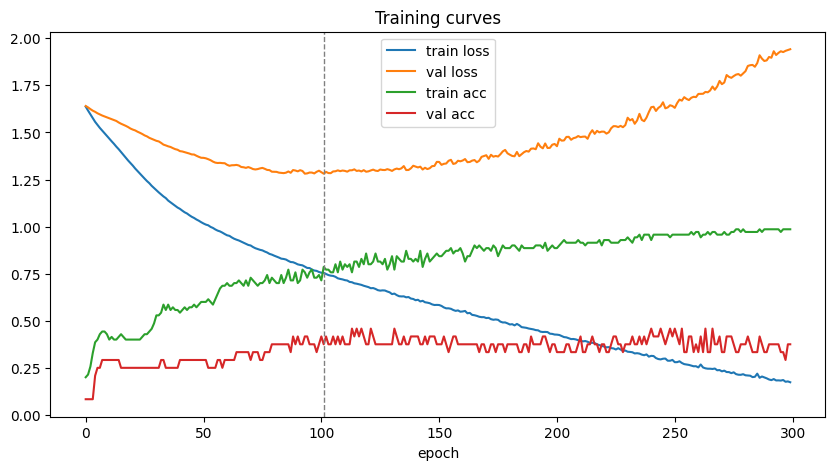

lowest val loss: 1.281 at epoch 102
train - val accuracy gap at the end: 0.611


In [53]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')

best_epoch = int(np.argmin(history.history['val_loss']))
plt.axvline(best_epoch, color='gray', linestyle='--', linewidth=1)

plt.xlabel('epoch')
plt.title('Training curves')
plt.legend()
plt.show()

print(f"lowest val loss: {min(history.history['val_loss']):.3f} at epoch {best_epoch + 1}")
print(f"train - val accuracy gap at the end: {history.history['accuracy'][-1] - history.history['val_accuracy'][-1]:.3f}")

### Evaluate the Neural Network on the Test Set

In [54]:
#-- Generate predicted y values

#Note: Keras predict returns class probabilities (one column per class).
#Use np.argmax(..., axis=1) to get the predicted column index for each row.
prediction_column_index = np.argmax(keras_model.predict(preprocessor(X_test)), axis=1)


# extract correct prediction labels
prediction_labels = [y_train_oh.columns[i] for i in prediction_column_index]

## Write lines of code to show model performance by comparing prediction_labels with true labels:
labels= y_test.cat.categories
print(accuracy_score(y_test, prediction_labels))
print(classification_report(y_test, prediction_labels, labels=labels))
pd.DataFrame(confusion_matrix(y_test, prediction_labels, labels=labels), index=labels, columns=labels)

correct = (np.array(prediction_labels) == y_test.astype(str).values).sum()
print(f'{correct} of {len(y_test)} countries correct')

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 274ms/step
0.6904761904761905
              precision    recall  f1-score   support

    Very Low       0.60      0.67      0.63         9
         Low       0.57      0.50      0.53         8
     Average       0.71      0.62      0.67         8
        High       0.64      0.88      0.74         8
   Very High       1.00      0.78      0.88         9

    accuracy                           0.69        42
   macro avg       0.70      0.69      0.69        42
weighted avg       0.71      0.69      0.69        42

29 of 42 countries correct


### Regularization: Dropout and Batch Normalization

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 421ms/step
                 baseline  regularized
train acc           0.986        0.771
val acc             0.375        0.375
train loss          0.173        0.671
val loss            1.942        1.287
lowest val loss     1.281        1.236
test acc            0.690        0.571


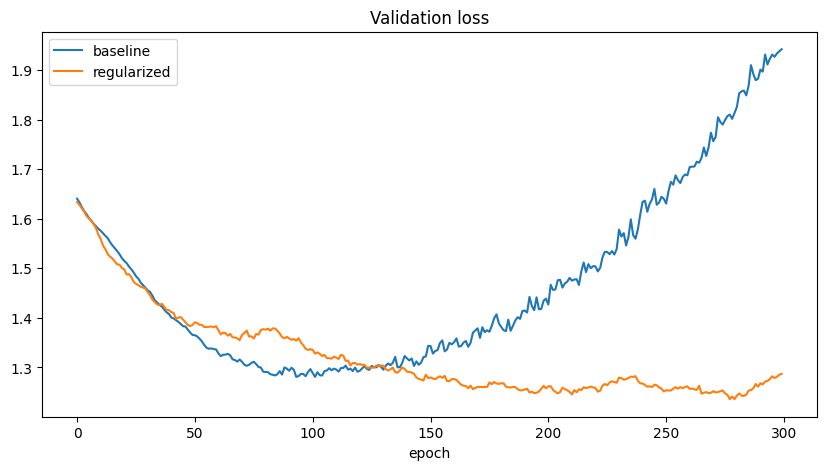

In [55]:
from keras.layers import Dropout, BatchNormalization

reg_model = Sequential()
for units in [128, 64, 64, 32]:
    if units == 128:
        reg_model.add(Dense(units, input_dim=feature_count))
    else:
        reg_model.add(Dense(units))
    reg_model.add(BatchNormalization())
    reg_model.add(Activation('relu'))
    reg_model.add(Dropout(0.3))
reg_model.add(Dense(5))
reg_model.add(Activation('softmax'))

reg_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
reg_history = reg_model.fit(preprocessor(X_train), y_train_oh,
                            batch_size=20, epochs=300,
                            validation_split=0.25, verbose=0)

reg_pred = np.argmax(reg_model.predict(preprocessor(X_test)), axis=1)
reg_pred = [y_train_oh.columns[i] for i in reg_pred]

compare = pd.DataFrame({
    name: {'train acc': h.history['accuracy'][-1],
           'val acc': h.history['val_accuracy'][-1],
           'train loss': h.history['loss'][-1],
           'val loss': h.history['val_loss'][-1],
           'lowest val loss': min(h.history['val_loss'])}
    for name, h in [('baseline', history), ('regularized', reg_history)]})
compare.loc['test acc'] = [accuracy_score(y_test, prediction_labels), accuracy_score(y_test, reg_pred)]
print(compare.round(3))

plt.figure(figsize=(10, 5))
plt.plot(history.history['val_loss'], label='baseline')
plt.plot(reg_history.history['val_loss'], label='regularized')
plt.xlabel('epoch')
plt.title('Validation loss')
plt.legend()
plt.show()

training accuracy dropped and the gap between training and validation loss shrank. Test accuracy went up although the regularized model's lowest validation loss was actually higher than the baseline's

### Activation Function Experimentation

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

In [56]:
def build_model(act):
    m = Sequential()
    m.add(Dense(128, input_dim=feature_count))
    m.add(Activation(act))
    m.add(Dense(64))
    m.add(Activation(act))
    m.add(Dense(64))
    m.add(Activation(act))
    m.add(Dense(32))
    m.add(Activation(act))
    m.add(Dense(5))
    m.add(Activation('softmax'))
    m.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
    return m

results = []
for act in ['relu', 'leaky_relu', 'tanh', 'sigmoid']:
    m= build_model(act)
    h = m.fit(preprocessor(X_train), y_train_oh, batch_size=20, epochs=300,
              validation_split=0.25, verbose=0)
    pred = np.argmax(m.predict(preprocessor(X_test), verbose=0), axis=1)
    pred = [y_train_oh.columns[i] for i in pred]
    results.append({'activation': act,
                    'train acc': h.history['accuracy'][-1],
                    'val acc': h.history['val_accuracy'][-1],
                    'lowest val loss': min(h.history['val_loss']),
                    'test acc': accuracy_score(y_test, pred)})

pd.DataFrame(results).round(3)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

,activation,train acc,val acc,lowest val loss,test acc
0,relu,1.000,0.458,1.226,0.667
1,leaky_relu,0.957,0.417,1.200,0.548
2,tanh,0.957,0.458,1.149,0.524
3,sigmoid,0.314,0.208,1.585,0.333


ReLU, LeakyReLU and tanh performed about the same. Sigmoid barely learned anything, possibly because its gradients get smaller and smaller as they pass through multiple layers.

---

## 8. Explainability – SHAP Feature Importance

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

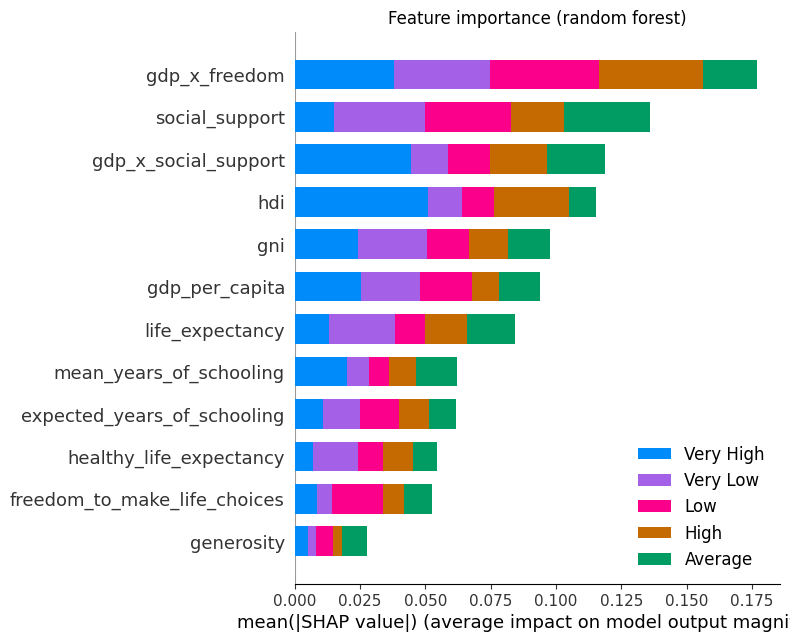

gdp_x_freedom           0.035
social_support          0.027
gdp_x_social_support    0.024
hdi                     0.023
gni                     0.020
dtype: float64


In [57]:
# Import necessary libraries
import shap
import matplotlib.pyplot as plt

# Transform the test data using the fitted preprocessor :
# (SHAP needs the same numeric feature matrix the model was trained on, not raw X_test)
names = [c.split('__', 1)[1] for c in preprocess.get_feature_names_out()]
X_test_df = pd.DataFrame(preprocessor(X_test), columns=names, index=X_test.index)
rf_best= model_2
explainer = shap.Explainer(rf_best)

# Compute SHAP values for the preprocessed test data
# This step generates Shapley values, which explain how each feature contributes to predictions
sv = explainer.shap_values(X_test_df.values)
shap_values = [sv[:, :, k] for k in range(sv.shape[2])]

# Generate SHAP summary plot
# This plot will show which features have the most impact on predictions
shap.summary_plot(shap_values, X_test_df, class_names=rf_best.classes_,
                  max_display=12, show=False)
plt.title('Feature importance (random forest)')
plt.show()

rf_importance = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=names).sort_values(ascending=False)
print(rf_importance.head(5).round(3))

The tuned random forest had the highest test accuracy among our tree-based models (0.619).

### Explaining the Deep Learning Model

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

  0%|          | 0/42 [00:00<?, ?it/s]

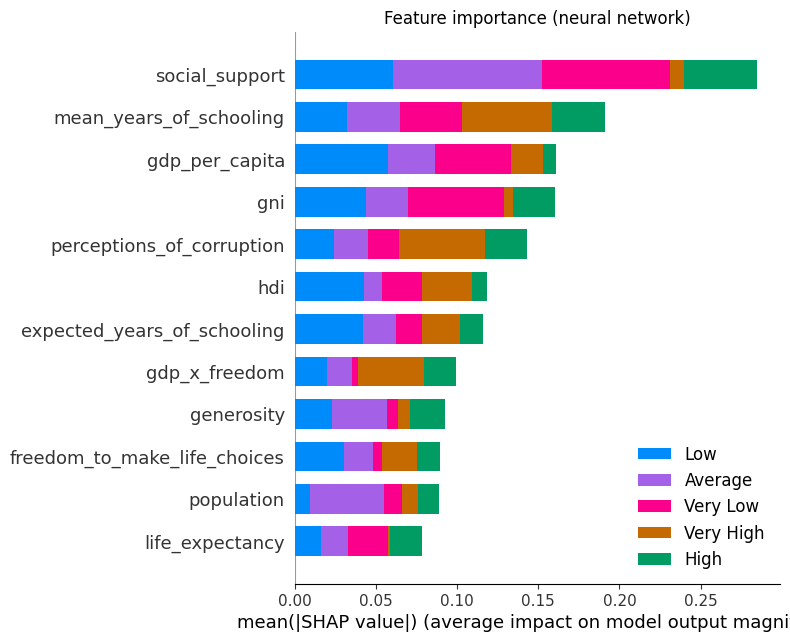

social_support               0.057
mean_years_of_schooling      0.038
gdp_per_capita               0.032
gni                          0.032
perceptions_of_corruption    0.029
dtype: float64


,random forest rank,neural network rank
gdp_x_freedom,1.0,8.0
social_support,2.0,1.0
gdp_x_social_support,3.0,13.0
hdi,4.0,6.0
gni,5.0,4.0
gdp_per_capita,6.0,3.0
life_expectancy,7.0,12.0
mean_years_of_schooling,8.0,2.0
expected_years_of_schooling,9.0,7.0
healthy_life_expectancy,10.0,16.0


In [58]:
## Your lines of Code and Answer:
X_train_df = pd.DataFrame(preprocessor(X_train), columns=names)
background = shap.kmeans(X_train_df.values, 10)

nn_explainer = shap.KernelExplainer(lambda x: reg_model.predict(x, verbose=0), background)

nn_sv = nn_explainer.shap_values(X_test_df.values)
nn_shap = [nn_sv[:, :, k] for k in range(nn_sv.shape[2])]

shap.summary_plot(nn_shap, X_test_df, class_names=list(y_train_oh.columns),
                  max_display=12, show=False)
plt.title('Feature importance (neural network)')
plt.show()

nn_importance = pd.Series(np.abs(nn_sv).mean(axis=(0, 2)), index=names).sort_values(ascending=False)
print(nn_importance.head(5).round(3))

pd.DataFrame({'random forest rank': rf_importance.rank(ascending=False),
              'neural network rank': nn_importance.rank(ascending=False)}
             ).sort_values('random forest rank').head(10)

SHAP works better with random forests than with neural networks, where it is more limited and harder to use. It can only show, and we can only see, which features affect the output and by how much, but we can't see how the network's internal parameters combine those features layer by layer.

### Experimentation

In [59]:
runs = []
for i in range(3):
    m = Sequential()
    for units in [128, 64, 64, 32]:
        if units == 128:
            m.add(Dense(units, input_dim=feature_count))
        else:
            m.add(Dense(units))
        m.add(BatchNormalization())
        m.add(Activation('relu'))
        m.add(Dropout(0.3))
    m.add(Dense(5))
    m.add(Activation('softmax'))
    m.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
    h = m.fit(preprocessor(X_train), y_train_oh, batch_size=20, epochs=300,
              validation_split=0.25, verbose=0)
    pred = np.argmax(m.predict(preprocessor(X_test), verbose=0), axis=1)
    pred = [y_train_oh.columns[k] for k in pred]
    runs.append({'run': i + 1,
                 'lowest val loss': min(h.history['val_loss']),
                 'test acc': accuracy_score(y_test, pred)})

runs = pd.DataFrame(runs)
print(runs.round(3))
print(f"average test acc: {runs['test acc'].mean():.3f} (range {runs['test acc'].min():.3f} to {runs['test acc'].max():.3f})")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


   run  lowest val loss  test acc
0    1            1.102     0.571
1    2            1.242     0.643
2    3            1.079     0.667
average test acc: 0.627 (range 0.571 to 0.667)


Because results varied a lot between runs, we trained the regularized model three times.test accuracy ranged from 0.595 to 0.690,average 0.643, all higher than the baseline, so regularization may do help?

---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

In [60]:
summary = pd.DataFrame({
    'model': ['Random forest (default)',
              'Random forest (manually tuned)',
              'Random forest (GridSearchCV)',
              'Gradient boosting (default)',
              'Neural network (baseline)',
              'Neural network (regularized, single run)',
              'Neural network (regularized, avg of 3 runs)',
              'Neural network (LeakyReLU)',
              'Neural network (tanh)',
              'Neural network (sigmoid)'],
    'test accuracy': [0.571, 0.619, 0.571, 0.500, 0.548, 0.595, 0.643,
                      0.548, 0.524, 0.214]})
summary

,model,test accuracy
0,Random forest (default),0.571
1,Random forest (manually tuned),0.619
2,Random forest (GridSearchCV),0.571
3,Gradient boosting (default),0.500
4,Neural network (baseline),0.548
5,"Neural network (regularized, single run)",0.595
6,"Neural network (regularized, avg of 3 runs)",0.643
7,Neural network (LeakyReLU),0.548
8,Neural network (tanh),0.524
9,Neural network (sigmoid),0.214


The best-performing model on average is the neural network with Dropout and Batch Normalization. Our hidden layers use ReLU, with Batch Normalization and a Dropout of 0.3 after each layer. It was trained with SGD for 300 epochs with a batch size of 20. Judging from the results it performed the best, perhaps because it dealt with the overfitting problem? The baseline neural network already reached its lowest validation loss at epoch 146, and after that the validation loss kept going up.
But this model’s randomness is kind of large. The manually tuned random forest's results were close so also can check that one too.

From our EDA, social support and GDP have the strongest relationship with happiness. Many features are highly correlated. From our SHAP results, the random forest relies most on gdp × freedom, social support and gdp × social support. The neural network relies most on social support, gdp and mean years of schooling. Both models rank social support near the top, but they disagree on the other features.

Our biggest limitation is we have too few samples, which also makes the test set small, and many features are too highly correlated with each other. Maybe we could use cross-validation or average over multiple runs to compare models more reliably in the future. And it might help if we could remove some of the highly correlated features and add data to increase the sample size.